# R4: Neural networks (MLP and CNN)
**F20DL Group 15 – Requirement R4.** Same task, data and split as R3: 5-class skin-disease classification, 1,623 images,
train 1,136 / validation 243 / test 244 (fixed, seed 42).

**What this notebook does**
1. **MLP** on the same 32×32 pixels the R3 models used (like-for-like with the Random Forest).
2. **Small CNN** trained from scratch on 128×128 images.
3. Both are tuned on the **validation** set using **macro-F1**, with **balanced class weights** in the loss.
4. The **test set is used once**, at the end, and the best model is compared with the best R3 model (Random Forest, test macro-F1 0.433).
5. **Watermark check:** I cover the bottom-left corner of the test images and see whether BCC recall drops (Section 8).

**Note on BCC:** about 72 % of basal cell carcinoma (BCC) photos carry the source atlas's watermark in the bottom-left corner,
so part of any model's BCC recall may come from the watermark rather than the lesion. BCC scores should be read with that in mind.

Runs on a normal laptop CPU in about 10–25 minutes (most of it is the 4 CNN runs). Let it finish.

## 1. Setup and package versions

In [6]:
import os, sys
DATA_DIR = next(p for p in ["../Fitzpatrick17k_processed", "Fitzpatrick17k_processed"] if os.path.exists(p))
sys.path.append(DATA_DIR)
from load_data import load_split, load_info, CLASS_NAMES

In [8]:
import time, json, random, copy, platform
from pathlib import Path
import numpy as np, pandas as pd, matplotlib, sklearn, PIL
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import (f1_score, accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_fscore_support)
from sklearn.utils.class_weight import compute_class_weight

# group rule: seed 42 everywhere, so I set it for python, numpy and torch
SEED = 42
def set_seed():
    # I call this before every model so each run gives the same numbers again
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
set_seed()

# scores go in notebooks/results, figures go in documentation/figures (same as the R3 notebooks)
RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)
FIG_DIR = Path("../documentation/figures") if Path("../documentation").exists() else Path("figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# printing my versions so they can go in the group requirements.txt
print("python      ", platform.python_version())
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("matplotlib  ", matplotlib.__version__)
print("pillow      ", PIL.__version__)
print("torch       ", torch.__version__)

Matplotlib is building the font cache; this may take a moment.


python       3.11.3
numpy        2.4.6
pandas       3.1.1
scikit-learn 1.9.1
matplotlib   3.11.2
pillow       13.0.0
torch        2.15.0


## 2. Load the data
We use the group loader only. The MLP gets 32×32 images flattened to 3,072 numbers (exactly the R3 input).
The CNN gets 128×128 images, which keep more texture detail.

In [9]:
SHORT = ["ACD", "BCC", "Psor", "SebD", "Vit"]       # short names so my plots aren't cluttered

# MLP data: 32x32 flattened, exactly what R3 used, so my MLP vs Random Forest is a fair comparison

X32_train, y_train = load_split("train", size=32, flatten=True)
X32_val,   y_val   = load_split("val",   size=32, flatten=True)
X32_test,  y_test  = load_split("test",  size=32, flatten=True)
# CNN data: 128x128 images (the loader default), more detail for the conv layers to pick up texture
X128_train, _ = load_split("train")                 # (n, 128, 128, 3)
X128_val,   _ = load_split("val")
X128_test,  _ = load_split("test")
print("MLP input:", X32_train.shape, "  CNN input:", X128_train.shape)

# the classes are imbalanced (psoriasis 604 vs seb. derm 123), so I use balanced class weights in the loss
# that way a mistake on a rare class costs more and the model can't just ignore it
class_w = compute_class_weight("balanced", classes=np.arange(5), y=y_train)
print("class weights:", dict(zip(SHORT, class_w.round(2))))

MLP input: (1136, 3072)   CNN input: (1136, 128, 128, 3)
class weights: {'ACD': np.float64(0.85), 'BCC': np.float64(0.92), 'Psor': np.float64(0.54), 'SebD': np.float64(2.64), 'Vit': np.float64(2.03)}


In [10]:
# here I turn the numpy arrays into torch tensors
# MLP: I standardise each pixel to mean 0, std 1 - only using TRAIN stats so no info leaks from val/test
mu, sd = X32_train.mean(0), X32_train.std(0) + 1e-6
def to_mlp(X): return torch.tensor((X - mu) / sd, dtype=torch.float32)

# CNN: I normalise each colour channel with the TRAIN mean/std
# torch wants (n, channels, height, width) so I swap the axes with transpose
ch_mean, ch_std = X128_train.mean((0, 1, 2)), X128_train.std((0, 1, 2))
def to_cnn(X): return torch.tensor(((X - ch_mean) / ch_std).transpose(0, 3, 1, 2).copy(), dtype=torch.float32)

mlp_train, mlp_val, mlp_test = to_mlp(X32_train), to_mlp(X32_val), to_mlp(X32_test)
cnn_train, cnn_val, cnn_test = to_cnn(X128_train), to_cnn(X128_val), to_cnn(X128_test)

## 3. Training function (used for both networks)
- **Loss:** cross-entropy with the balanced class weights.
- **Optimiser:** Adam, the standard choice; it adapts the step size for each weight, so only the learning rate needs tuning.
- **Early stopping:** after every epoch we measure **validation macro-F1** and keep the weights from the best epoch.
  We stop when it hasn't improved for `patience` epochs. So the number of epochs is also picked on validation.
- **Augmentation (CNN only, training images only):** random horizontal/vertical flips. A skin lesion has no "up" direction,
  so a flipped photo is still a realistic example, which helps against overfitting.

In [11]:
# macro-F1 is our group's main metric (every class counts equally, even the small ones)
def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")

# predict in chunks of 128 so it doesn't eat all my RAM
def predict(model, X):
    model.eval()                                             # turns dropout off for predicting
    with torch.no_grad():
        return torch.cat([model(X[i:i + 128]) for i in range(0, len(X), 128)]).argmax(1).numpy()

# my training loop - I use the same one for the MLP and the CNN so they're trained the same way
def train(model, X_tr, X_va, lr, epochs, patience, batch_size, flips=False):
    set_seed()
    # weighted cross-entropy = the class imbalance fix
    loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(class_w, dtype=torch.float32))
    # Adam with a small weight decay (1e-4) to keep the weights from getting too big
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    y_tr = torch.tensor(y_train)
    best_f1, best_epoch, best_state, history = -1, 0, None, []
    for epoch in range(1, epochs + 1):
        model.train()                                        # dropout on while training
        order = torch.randperm(len(X_tr))                    # shuffle the training images every epoch
        total = 0
        for i in range(0, len(order), batch_size):
            idx = order[i:i + batch_size]
            xb = X_tr[idx]
            if flips:                                        # random flips, a new choice every batch
                if random.random() < 0.5: xb = xb.flip(3)
                if random.random() < 0.5: xb = xb.flip(2)
            loss = loss_fn(model(xb), y_tr[idx])
            opt.zero_grad(); loss.backward(); opt.step()     # the usual backprop step
            total += loss.item() * len(idx)
        # after each epoch I check macro-F1 on validation (never test!)
        f1 = macro_f1(y_val, predict(model, X_va))
        history.append({"epoch": epoch, "train_loss": total / len(X_tr), "val_macro_f1": f1})
        # I keep a copy of the weights from the best epoch so far
        if f1 > best_f1:
            best_f1, best_epoch, best_state = f1, epoch, copy.deepcopy(model.state_dict())
        elif epoch - best_epoch >= patience:
            break                                            # early stopping
    model.load_state_dict(best_state)                        # go back to the best epoch
    return model, pd.DataFrame(history), best_f1, best_epoch

# plots the training loss and val macro-F1 per epoch, and saves it for the report

def plot_curves(history, best_epoch, name):
    fig, ax = plt.subplots(1, 2, figsize=(9, 3))
    ax[0].plot(history.epoch, history.train_loss); ax[0].set_title(f"{name}: training loss"); ax[0].set_xlabel("epoch")
    ax[1].plot(history.epoch, history.val_macro_f1, color="C2"); ax[1].set_title(f"{name}: validation macro-F1")
    ax[1].axvline(best_epoch, ls="--", color="grey", label=f"kept epoch {best_epoch}"); ax[1].legend(); ax[1].set_xlabel("epoch")
    plt.tight_layout(); fig.savefig(FIG_DIR / f"R4_curves_{name}.png", dpi=200); plt.show()

## 4. MLP

**Model:** 3,072 inputs → hidden layer(s) with ReLU and dropout → 5 outputs.

**Hyperparameters tried (2 × 2 × 2 = 8 settings, best by validation macro-F1):**
- **Hidden layers** (256) or (512, 128): one small layer vs. two bigger layers. We only have 1,136 training images,
  so we check whether more capacity helps or just overfits.
- **Learning rate** 1e-3 or 1e-4: 1e-3 is Adam's usual default; 1e-4 is slower but steadier.
- **Dropout** 0.2 or 0.5: dropout switches off random neurons while training, which reduces overfitting. 0.5 is strong, 0.2 is light.
- **Fixed:** batch size 64, weight decay 1e-4 (a small penalty on large weights), up to 100 epochs, early stopping patience 15.

In [12]:
# builds the MLP: Linear -> ReLU -> Dropout for each hidden layer, then 5 outputs (one per class)
def make_mlp(hidden, dropout):
    layers, size = [], 3072
    for h in hidden:
        layers += [nn.Linear(size, h), nn.ReLU(), nn.Dropout(dropout)]
        size = h
    layers.append(nn.Linear(size, 5))
    return nn.Sequential(*layers)

# my grid search: 2 x 2 x 2 = 8 MLPs, each scored on validation macro-F1
mlp_rows, mlp_runs = [], []
for hidden in [(256,), (512, 128)]:
    for lr in [1e-3, 1e-4]:
        for dropout in [0.2, 0.5]:
            set_seed()
            model, hist, f1, ep = train(make_mlp(hidden, dropout), mlp_train, mlp_val, lr, epochs=100, patience=15, batch_size=64)
            train_f1 = macro_f1(y_train, predict(model, mlp_train))   # train score too, to spot overfitting
            mlp_rows.append({"hidden": str(hidden), "lr": lr, "dropout": dropout, "best_epoch": ep,
                             "train_macro_f1": round(train_f1, 3), "val_macro_f1": round(f1, 3)})
            mlp_runs.append((model, hist, ep))
            print(mlp_rows[-1])

mlp_search = pd.DataFrame(mlp_rows)
mlp_search.to_csv(RESULTS_DIR / "R4_MLP_val_search.csv", index=False)
# I pick the setting with the highest validation macro-F1
best = int(mlp_search.val_macro_f1.idxmax())
mlp_model, mlp_hist, mlp_ep = mlp_runs[best]
mlp_params = mlp_search.iloc[best][["hidden", "lr", "dropout", "best_epoch"]].to_dict()
print("\nChosen MLP:", mlp_params)
mlp_search.sort_values("val_macro_f1", ascending=False)

{'hidden': '(256,)', 'lr': 0.001, 'dropout': 0.2, 'best_epoch': 41, 'train_macro_f1': 0.992, 'val_macro_f1': 0.451}
{'hidden': '(256,)', 'lr': 0.001, 'dropout': 0.5, 'best_epoch': 47, 'train_macro_f1': 0.968, 'val_macro_f1': 0.45}
{'hidden': '(256,)', 'lr': 0.0001, 'dropout': 0.2, 'best_epoch': 14, 'train_macro_f1': 0.764, 'val_macro_f1': 0.443}
{'hidden': '(256,)', 'lr': 0.0001, 'dropout': 0.5, 'best_epoch': 27, 'train_macro_f1': 0.825, 'val_macro_f1': 0.454}
{'hidden': '(512, 128)', 'lr': 0.001, 'dropout': 0.2, 'best_epoch': 17, 'train_macro_f1': 0.935, 'val_macro_f1': 0.441}
{'hidden': '(512, 128)', 'lr': 0.001, 'dropout': 0.5, 'best_epoch': 18, 'train_macro_f1': 0.694, 'val_macro_f1': 0.454}
{'hidden': '(512, 128)', 'lr': 0.0001, 'dropout': 0.2, 'best_epoch': 18, 'train_macro_f1': 0.812, 'val_macro_f1': 0.453}
{'hidden': '(512, 128)', 'lr': 0.0001, 'dropout': 0.5, 'best_epoch': 32, 'train_macro_f1': 0.788, 'val_macro_f1': 0.447}

Chosen MLP: {'hidden': '(256,)', 'lr': 0.0001, 'drop

,hidden,lr,dropout,best_epoch,train_macro_f1,val_macro_f1
3,"(256,)",0.0001,0.5,27,0.825,0.454
5,"(512, 128)",0.0010,0.5,18,0.694,0.454
6,"(512, 128)",0.0001,0.2,18,0.812,0.453
0,"(256,)",0.0010,0.2,41,0.992,0.451
1,"(256,)",0.0010,0.5,47,0.968,0.450
7,"(512, 128)",0.0001,0.5,32,0.788,0.447
2,"(256,)",0.0001,0.2,14,0.764,0.443
4,"(512, 128)",0.0010,0.2,17,0.935,0.441


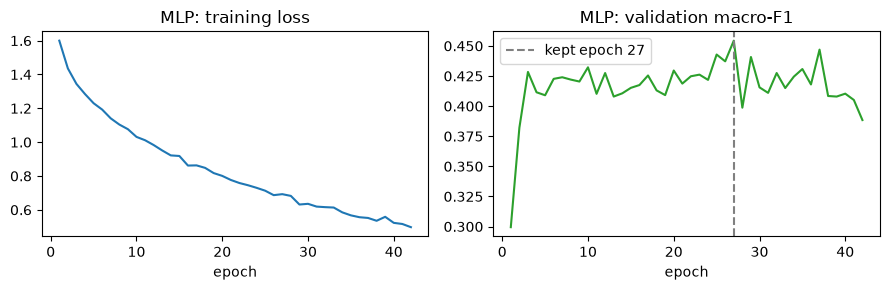

In [13]:
plot_curves(mlp_hist, mlp_ep, "MLP")

## 5. Small CNN (from scratch)

**Model:** 4 blocks of [3×3 convolution → batch norm → ReLU → 2×2 max-pool] with 16, 32, 64, 128 filters,
then global average pooling → dropout → 5 outputs. Convolution filters slide over the whole image, so the network learns local
patterns (texture, colour, edges of a lesion) with far fewer weights than the MLP. Batch norm makes training faster and more stable.

**Hyperparameters tried (2 × 2 = 4 settings, best by validation macro-F1):**
- **Learning rate** 1e-3 or 3e-4: Adam's default and a ~3× smaller, safer value.
- **Flip augmentation** on or off: we test whether flipping training images reduces overfitting.
- **Fixed:** dropout 0.3, batch size 32, weight decay 1e-4, up to 30 epochs, early stopping patience 6
  (kept small because each CNN epoch is slow on a CPU).

In [14]:
# my small CNN: 4 conv blocks, each one halves the image size (128 -> 64 -> 32 -> 16 -> 8)
# then global average pooling squashes each filter to one number, dropout, and 5 outputs
def make_cnn(dropout=0.3):
    layers, c_in = [], 3
    for c in [16, 32, 64, 128]:
        layers += [nn.Conv2d(c_in, c, 3, padding=1), nn.BatchNorm2d(c), nn.ReLU(), nn.MaxPool2d(2)]
        c_in = c
    layers += [nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(c_in, 5)]
    return nn.Sequential(*layers)

# only 4 settings because CNN training is slow on my laptop CPU (learning rate x flips on/off)
cnn_rows, cnn_runs = [], []
for lr in [1e-3, 3e-4]:
    for flips in [True, False]:
        t0 = time.time()
        set_seed()
        model, hist, f1, ep = train(make_cnn(), cnn_train, cnn_val, lr, epochs=30, patience=6, batch_size=32, flips=flips)
        train_f1 = macro_f1(y_train, predict(model, cnn_train))
        cnn_rows.append({"lr": lr, "flips": flips, "best_epoch": ep, "train_macro_f1": round(train_f1, 3),
                         "val_macro_f1": round(f1, 3), "minutes": round((time.time() - t0) / 60, 1)})
        cnn_runs.append((model, hist, ep))
        print(cnn_rows[-1])

cnn_search = pd.DataFrame(cnn_rows)
cnn_search.to_csv(RESULTS_DIR / "R4_CNN_val_search.csv", index=False)
# again I keep whichever had the best validation macro-F1
best = int(cnn_search.val_macro_f1.idxmax())
cnn_model, cnn_hist, cnn_ep = cnn_runs[best]
cnn_params = cnn_search.iloc[best][["lr", "flips", "best_epoch"]].to_dict()
print("\nChosen CNN:", cnn_params)
cnn_search.sort_values("val_macro_f1", ascending=False)

{'lr': 0.001, 'flips': True, 'best_epoch': 23, 'train_macro_f1': 0.545, 'val_macro_f1': 0.527, 'minutes': 16.8}
{'lr': 0.001, 'flips': False, 'best_epoch': 13, 'train_macro_f1': 0.549, 'val_macro_f1': 0.549, 'minutes': 11.0}
{'lr': 0.0003, 'flips': True, 'best_epoch': 13, 'train_macro_f1': 0.478, 'val_macro_f1': 0.484, 'minutes': 7.5}
{'lr': 0.0003, 'flips': False, 'best_epoch': 13, 'train_macro_f1': 0.52, 'val_macro_f1': 0.498, 'minutes': 3.9}

Chosen CNN: {'lr': 0.001, 'flips': False, 'best_epoch': 13}


,lr,flips,best_epoch,train_macro_f1,val_macro_f1,minutes
1,0.0010,False,13,0.549,0.549,11.0
0,0.0010,True,23,0.545,0.527,16.8
3,0.0003,False,13,0.520,0.498,3.9
2,0.0003,True,13,0.478,0.484,7.5


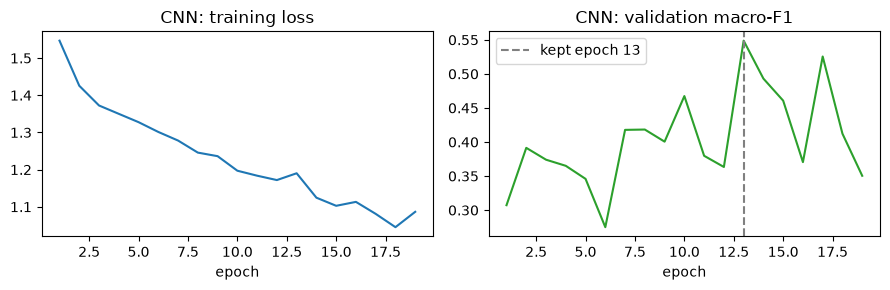

In [15]:
plot_curves(cnn_hist, cnn_ep, "CNN")

## 6. Test set (used once)
Both models are now fixed. We score each one **once** on the 244 test images, in the same format as R3
(`results/test_<model>.csv` and a confusion matrix in `documentation/figures/`).

MLP: TEST accuracy = 0.492 | TEST macro-F1 = 0.452

                             precision    recall  f1-score   support

allergic contact dermatitis      0.451     0.404     0.426        57
       basal cell carcinoma      0.579     0.611     0.595        54
                  psoriasis      0.595     0.522     0.556        90
      seborrheic dermatitis      0.257     0.474     0.333        19
                   vitiligo      0.364     0.333     0.348        24

                   accuracy                          0.492       244
                  macro avg      0.449     0.469     0.452       244
               weighted avg      0.509     0.492     0.496       244



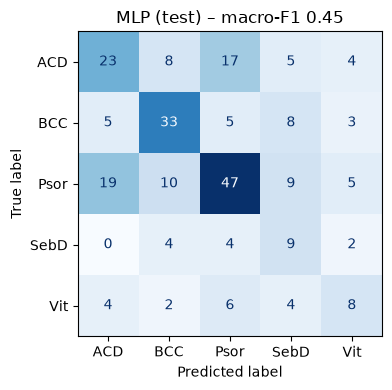

CNN: TEST accuracy = 0.488 | TEST macro-F1 = 0.464

                             precision    recall  f1-score   support

allergic contact dermatitis      0.558     0.421     0.480        57
       basal cell carcinoma      0.659     0.500     0.568        54
                  psoriasis      0.545     0.533     0.539        90
      seborrheic dermatitis      0.210     0.684     0.321        19
                   vitiligo      0.700     0.292     0.412        24

                   accuracy                          0.488       244
                  macro avg      0.534     0.486     0.464       244
               weighted avg      0.562     0.488     0.502       244



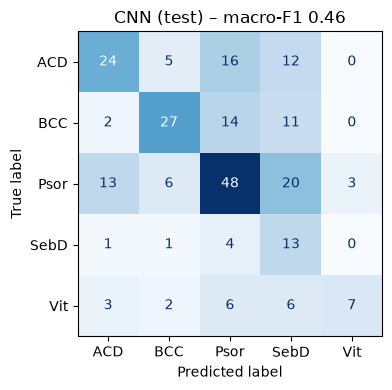

Best R4 model (by validation macro-F1): CNN


In [16]:
# same output format as Adhil/Abhinav's R3 notebooks so the numbers line up in one table
def evaluate_on_test(name, y_pred, params):
    acc, mf1 = accuracy_score(y_test, y_pred), macro_f1(y_test, y_pred)
    p, r, _, _ = precision_recall_fscore_support(y_test, y_pred, labels=range(5), zero_division=0)
    print(f"{name}: TEST accuracy = {acc:.3f} | TEST macro-F1 = {mf1:.3f}\n")
    print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3, zero_division=0))
    fig, ax = plt.subplots(figsize=(4.6, 4))
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=range(5)), display_labels=SHORT).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name} (test) – macro-F1 {mf1:.2f}")
    plt.tight_layout(); fig.savefig(FIG_DIR / f"cm_{name}.png", dpi=200); plt.show()
    res = {"model": name, "test_accuracy": round(acc, 4), "test_macro_f1": round(mf1, 4), "params": json.dumps(params, default=str)}
    for i, c in enumerate(SHORT):
        res[f"P_{c}"], res[f"R_{c}"] = round(p[i], 3), round(r[i], 3)
    pd.DataFrame([res]).to_csv(RESULTS_DIR / f"test_{name}.csv", index=False)
    return res

# this is the ONLY time I touch the test set
mlp_pred = predict(mlp_model, mlp_test)
cnn_pred = predict(cnn_model, cnn_test)
mlp_res = evaluate_on_test("MLP", mlp_pred, mlp_params)
cnn_res = evaluate_on_test("CNN", cnn_pred, cnn_params)

# I choose my best R4 model by VALIDATION score, not test, so the test set stays fair
BEST = "CNN" if cnn_search.val_macro_f1.max() >= mlp_search.val_macro_f1.max() else "MLP"
best_pred = cnn_pred if BEST == "CNN" else mlp_pred
print("Best R4 model (by validation macro-F1):", BEST)

## 7. Comparison with the best R3 model (Random Forest)
We refit R3's Random Forest with its chosen settings (same data, same seed) to get its predictions on the same test images.

**Is the gain meaningful?** A **bootstrap**: we resample the 244 test images 2,000 times and recompute
*macro-F1(R4) − macro-F1(Random Forest)* each time. If the 95 % range stays above 0, the gain is unlikely to be luck.

In [17]:
# I retrain R3's best Random Forest with exactly their settings, so I have its predictions on the same test images
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=200, max_features=0.1, min_samples_leaf=1, class_weight="balanced",
                            random_state=42, n_jobs=-1).fit(X32_train, y_train)
rf_pred = rf.predict(X32_test)
print(f"Random Forest: test macro-F1 {macro_f1(y_test, rf_pred):.3f} (R3 reported 0.433)")

def row(name, y_pred):
    recall = precision_recall_fscore_support(y_test, y_pred, labels=range(5), zero_division=0)[1]
    return {"model": name, "macro_F1": round(macro_f1(y_test, y_pred), 3), "accuracy": round(accuracy_score(y_test, y_pred), 3),
            **{f"recall_{c}": round(v, 2) for c, v in zip(SHORT, recall)}}
# my comparison table: macro-F1, accuracy and recall per class
comparison = pd.DataFrame([row("Random Forest (best R3)", rf_pred), row("MLP", mlp_pred), row("CNN", cnn_pred)])
comparison.to_csv(RESULTS_DIR / "R4_vs_RF.csv", index=False)

# bootstrap: resample the test set 2000 times and see how often my model really beats the forest
rng = np.random.default_rng(SEED)
diffs = []
for _ in range(2000):
    i = rng.integers(0, len(y_test), len(y_test))          # resample test images with replacement
    diffs.append(macro_f1(y_test[i], best_pred[i]) - macro_f1(y_test[i], rf_pred[i]))
low, high = np.percentile(diffs, [2.5, 97.5])
print(f"{BEST} minus Random Forest, macro-F1: {np.mean(diffs):+.3f}  (95% range {low:+.3f} to {high:+.3f})")
print("Meaningful gain (range above 0)?", "YES" if low > 0 else "NO, could be chance")
comparison

Random Forest: test macro-F1 0.427 (R3 reported 0.433)
CNN minus Random Forest, macro-F1: +0.037  (95% range -0.043 to +0.115)
Meaningful gain (range above 0)? NO, could be chance


,model,macro_F1,accuracy,recall_ACD,recall_BCC,recall_Psor,recall_SebD,recall_Vit
0,Random Forest (best R3),0.427,0.496,0.35,0.59,0.63,0.21,0.33
1,MLP,0.452,0.492,0.40,0.61,0.52,0.47,0.33
2,CNN,0.464,0.488,0.42,0.50,0.53,0.68,0.29


## 8. Watermark check (BCC)
About 72 % of BCC photos carry the source atlas's watermark in the **bottom-left corner** (found in R2), and R3's Random Forest
importance map had a hot spot there. So I cover that corner (bottom 25 % × left 35 % of each test image) with plain grey and predict again.
No retraining, it only takes a few seconds. If BCC recall drops a lot, the model was partly using the watermark instead of the skin.

In [18]:
# I cover the bottom-left corner (where the watermark sits) with plain grey
def cover_corner(X):                       # X: (n, H, W, 3) images with values 0-1
    X = X.copy(); H, W = X.shape[1:3]
    X[:, H - H // 4:, :int(W * 0.35)] = 0.5
    return X

# BCC recall = how many of the real BCC images the model finds
def bcc_recall(y_pred): return ((y_pred == 1) & (y_test == 1)).sum() / (y_test == 1).sum()

X32_test_cov = cover_corner(X32_test.reshape(-1, 32, 32, 3)).reshape(-1, 3072)
# predict again on the covered images - if BCC recall drops a lot, the model was using the watermark
preds_cov = {"Random Forest": rf.predict(X32_test_cov),
             "MLP": predict(mlp_model, to_mlp(X32_test_cov)),
             "CNN": predict(cnn_model, to_cnn(cover_corner(X128_test)))}
preds = {"Random Forest": rf_pred, "MLP": mlp_pred, "CNN": cnn_pred}
watermark = pd.DataFrame([{"model": m, "BCC_recall": round(bcc_recall(preds[m]), 3),
                           "BCC_recall_corner_covered": round(bcc_recall(preds_cov[m]), 3),
                           "macro_F1": round(macro_f1(y_test, preds[m]), 3),
                           "macro_F1_corner_covered": round(macro_f1(y_test, preds_cov[m]), 3)} for m in preds])
watermark.to_csv(RESULTS_DIR / "R4_watermark_check.csv", index=False)
watermark

,model,BCC_recall,BCC_recall_corner_covered,macro_F1,macro_F1_corner_covered
0,Random Forest,0.593,0.519,0.427,0.433
1,MLP,0.611,0.537,0.452,0.402
2,CNN,0.500,0.519,0.464,0.460


## 9. Summary

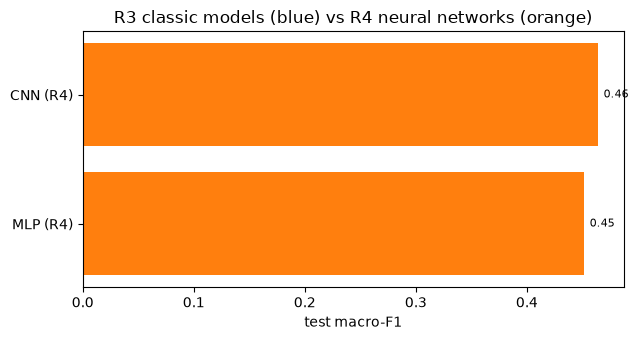

,model,test_macro_f1,test_accuracy
1,CNN (R4),0.4641,0.4877
0,MLP (R4),0.4516,0.4918


In [19]:
# final chart: all R3 models and my two networks on the same test set
# (if the R3 table is missing or has other column names, I just plot my own two models instead of crashing)
r3_file = RESULTS_DIR / "R3_comparison_table.csv"
r3 = pd.read_csv(r3_file) if r3_file.exists() else pd.DataFrame()
r3 = r3[["model", "test_macro_f1", "test_accuracy"]] if {"model", "test_macro_f1", "test_accuracy"} <= set(r3.columns) else pd.DataFrame()
summary = pd.concat([r3, pd.DataFrame([{"model": "MLP (R4)", "test_macro_f1": mlp_res["test_macro_f1"], "test_accuracy": mlp_res["test_accuracy"]},
                                       {"model": "CNN (R4)", "test_macro_f1": cnn_res["test_macro_f1"], "test_accuracy": cnn_res["test_accuracy"]}])])
summary = summary.sort_values("test_macro_f1")
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.barh(summary.model, summary.test_macro_f1, color=["C1" if "R4" in m else "C0" for m in summary.model])
for k, v in enumerate(summary.test_macro_f1): ax.text(v + 0.005, k, f"{v:.2f}", va="center", fontsize=8)
ax.set_xlabel("test macro-F1"); ax.set_title("R3 classic models (blue) vs R4 neural networks (orange)")
plt.tight_layout(); fig.savefig(FIG_DIR / "R4_vs_R3.png", dpi=200); plt.show()
summary.sort_values("test_macro_f1", ascending=False)

**Interpretation.** Both networks beat the best classic model on test macro-F1 (MLP 0.452, CNN 0.464 vs Random Forest 0.427), mainly by recognising far more seborrheic dermatitis cases (CNN recall 0.68 vs 0.21). However, the bootstrap 95% range for CNN − Random Forest (−0.043 to +0.115) includes 0, so the gain may be due to chance on a 244-image test set. The MLP overfits strongly (train macro-F1 up to 0.99 vs ~0.45 on validation), while the CNN shows no overfitting (train ≈ validation ≈ 0.55), suggesting it could benefit from more capacity or training. Covering the watermark corner reduced BCC recall for the Random Forest (0.59 → 0.52) and the MLP (0.61 → 0.54) but not for the CNN (0.50 → 0.52), indicating the pixel-based models partly relied on the watermark while the CNN relied on the lesion itself. The re-trained Random Forest scored 0.427 rather than R3's 0.433, likely due to small differences in package versions.